<a href="https://colab.research.google.com/github/Aumkaragrawal02/netflix-content-analysis/blob/main/Mini_Project_PSC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports and upload

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

# Load and first look

In [ ]:
df = pd.read_csv('netflix_titles.csv')
print('Shape:', df.shape)
display(df.head())
df.info()
print(df.describe(include='all').T)

Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
               count unique  \
show_id         8807   8807   
type            8807      2   
title           8807   8807   
director        6173   4528   
cast            7982   7692   
country         7976    748   
date_added      8797   1767   
rele

# Missing values

In [ ]:
missing = pd.DataFrame({'missing': df.isna().sum(),
                        'percent': (df.isna().mean() * 100).round(2)})
print(missing[missing.missing > 0].sort_values('missing', ascending=False))

# Rating column has 3 rows where the duration was entered by mistake
bad = df['rating'].astype(str).str.contains('min', na=False)
print('Rows with duration stored in rating:', bad.sum())
df.loc[bad, 'duration'] = df.loc[bad, 'rating']
df.loc[bad, 'rating'] = np.nan

# Fill / drop strategy
for col in ['director', 'cast', 'country']:
    df[col] = df[col].fillna('Unknown')
df['rating'] = df['rating'].fillna('Not Rated')
df = df.dropna(subset=['date_added', 'duration']).reset_index(drop=True)
print('Missing values left:', df.isna().sum().sum())

            missing  percent
director       2634    29.91
country         831     9.44
cast            825     9.37
date_added       10     0.11
rating            4     0.05
duration          3     0.03
Rows with duration stored in rating: 3
Missing values left: 0


# Duplicates

In [ ]:
print('Fully duplicated rows :', df.duplicated().sum())
print('Duplicate show_id     :', df['show_id'].duplicated().sum())
print('Duplicate title+type+year:', df.duplicated(subset=['title', 'type', 'release_year']).sum())
df = df.drop_duplicates().drop_duplicates(subset=['title', 'type', 'release_year']).reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Fully duplicated rows : 0
Duplicate show_id     : 0
Duplicate title+type+year: 0
Shape after removing duplicates: (8797, 12)


# Data types and feature engineering

In [ ]:
for col in ['type', 'title', 'director', 'cast', 'country', 'rating', 'listed_in', 'description']:
    df[col] = df[col].astype(str).str.strip()

df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), format='%B %d, %Y')
df['year_added'] = df['date_added'].dt.year.astype(int)
df['month_added'] = df['date_added'].dt.month_name()

df['duration_value'] = df['duration'].str.extract(r'(\d+)')[0].astype(int)
df['duration_min'] = np.where(df['type'] == 'Movie', df['duration_value'], np.nan)
df['seasons'] = np.where(df['type'] == 'TV Show', df['duration_value'], np.nan)

df['type'] = df['type'].astype('category')
df['rating'] = df['rating'].astype('category')
print(df.dtypes)

show_id                   object
type                    category
title                     object
director                  object
cast                      object
country                   object
date_added        datetime64[ns]
release_year               int64
rating                  category
duration                  object
listed_in                 object
description               object
year_added                 int64
month_added               object
duration_value             int64
duration_min             float64
seasons                  float64
dtype: object


# Outliers (IQR method)

                 Column  Lower bound  Upper bound  Outliers
0  Movie duration (min)         46.5        154.5       450
1            TV seasons         -0.5          3.5       254
2          Release year       2004.0       2028.0       717


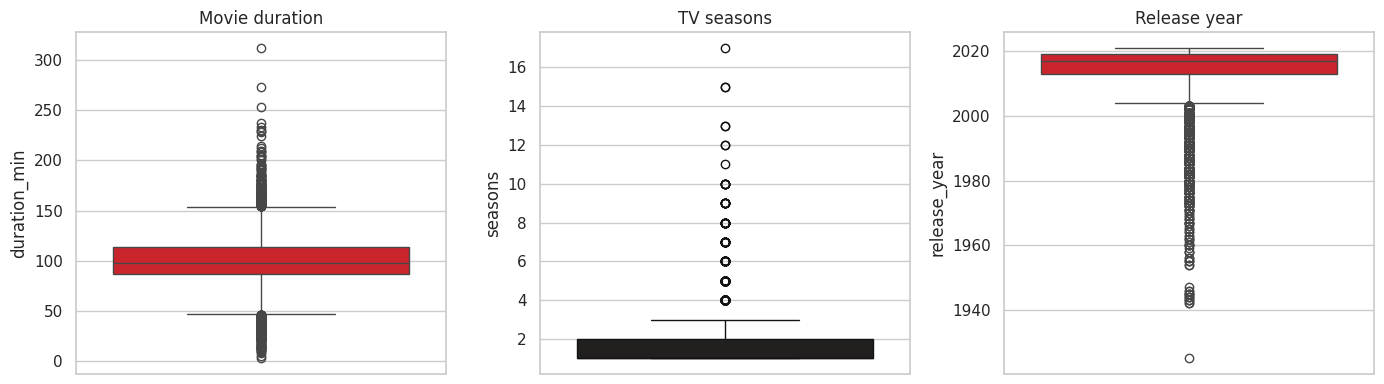

Flagged movie-duration outliers: 450


In [ ]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for name, s in [('Movie duration (min)', df['duration_min'].dropna()),
                ('TV seasons', df['seasons'].dropna()),
                ('Release year', df['release_year'])]:
    lo, hi = iqr_bounds(s)
    rows.append([name, lo, hi, ((s < lo) | (s > hi)).sum()])
print(pd.DataFrame(rows, columns=['Column', 'Lower bound', 'Upper bound', 'Outliers']))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=df['duration_min'].dropna(), ax=ax[0], color='#E50914'); ax[0].set_title('Movie duration')
sns.boxplot(y=df['seasons'].dropna(), ax=ax[1], color='#221f1f');       ax[1].set_title('TV seasons')
sns.boxplot(y=df['release_year'], ax=ax[2], color='#E50914');           ax[2].set_title('Release year')
plt.tight_layout(); plt.show()

# Outliers are genuine (long films, old classics, long-running shows) -> flag, don't delete
lo, hi = iqr_bounds(df['duration_min'].dropna())
df['duration_outlier'] = (df['duration_min'] < lo) | (df['duration_min'] > hi)
print('Flagged movie-duration outliers:', df['duration_outlier'].sum())

# Save cleaned data

In [ ]:
df.to_csv('netflix_cleaned.csv', index=False)
print('Final shape:', df.shape)

Final shape: (8797, 18)


# Viz 1, Movies vs TV Shows

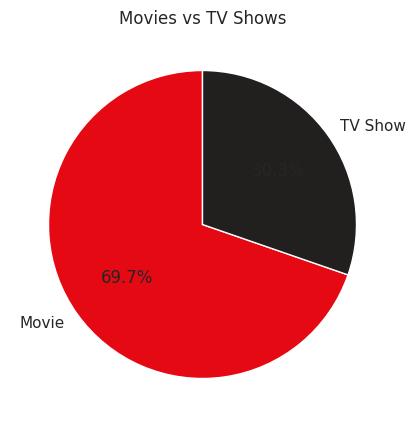

In [ ]:
counts = df['type'].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#E50914', '#221f1f'], startangle=90)
plt.title('Movies vs TV Shows'); plt.show()

# Viz 2, Titles added per year

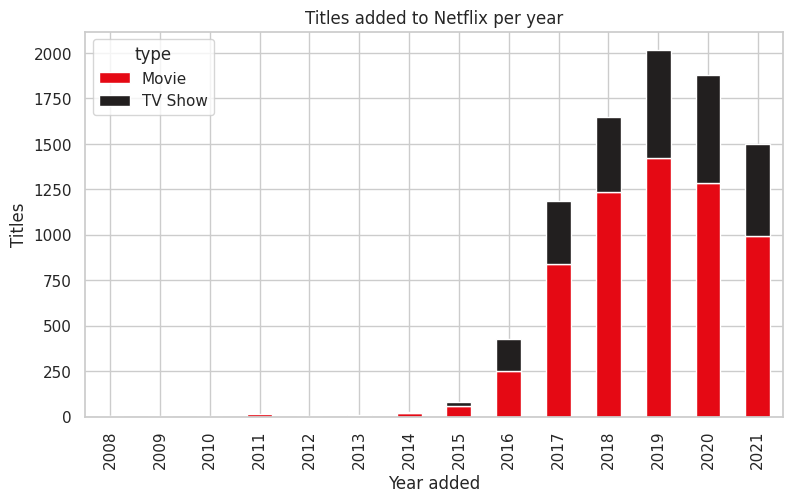

In [ ]:
yearly = df.groupby(['year_added', 'type']).size().unstack(fill_value=0)
yearly.plot(kind='bar', stacked=True, color=['#E50914', '#221f1f'])
plt.title('Titles added to Netflix per year'); plt.xlabel('Year added'); plt.ylabel('Titles'); plt.show()

# Viz 3, Top 10 countries

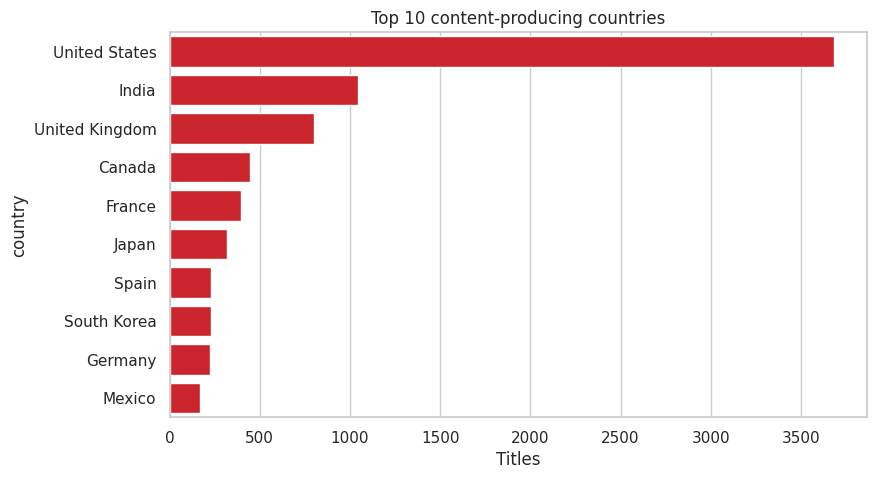

In [ ]:
countries = df['country'].str.split(', ').explode().str.strip()
top_c = countries[~countries.isin(['Unknown', ''])].value_counts().head(10)
sns.barplot(x=top_c.values, y=top_c.index, color='#E50914')
plt.title('Top 10 content-producing countries'); plt.xlabel('Titles'); plt.show()

# Viz 4, Top 10 genres

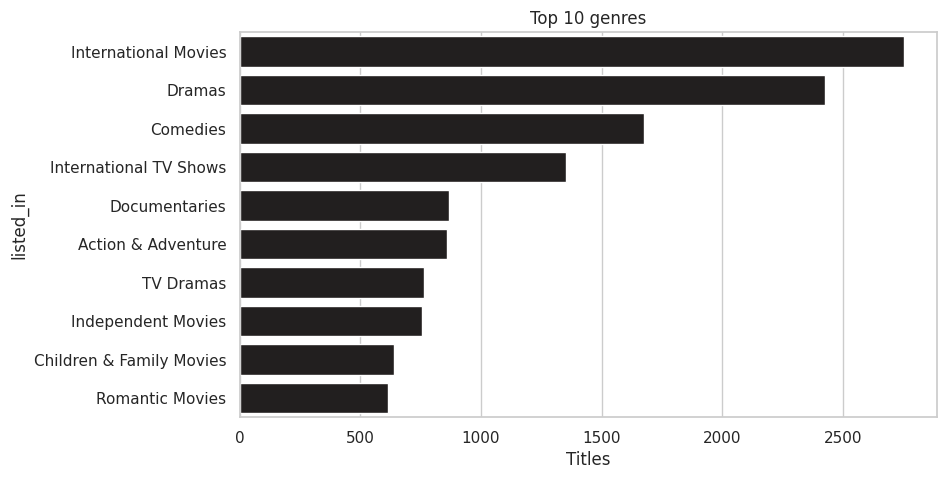

In [ ]:
top_g = df['listed_in'].str.split(', ').explode().value_counts().head(10)
sns.barplot(x=top_g.values, y=top_g.index, color='#221f1f')
plt.title('Top 10 genres'); plt.xlabel('Titles'); plt.show()

# Viz 5, Rating distribution

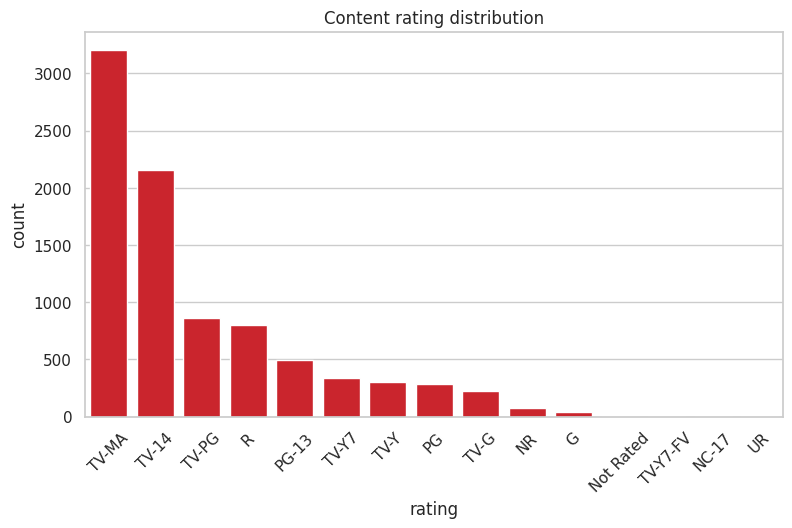

In [ ]:
order = df['rating'].value_counts().index
sns.countplot(data=df, x='rating', order=order, color='#E50914')
plt.title('Content rating distribution'); plt.xticks(rotation=45); plt.show()

# Viz 6, Movie duration histogram

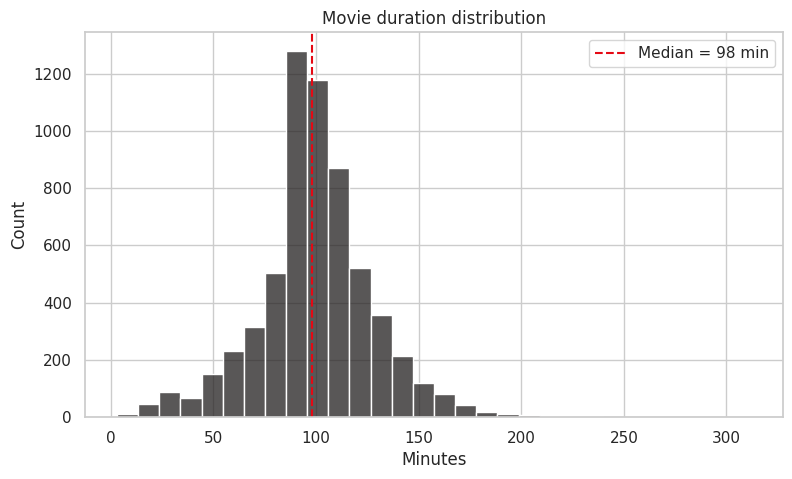

In [ ]:
sns.histplot(df['duration_min'].dropna(), bins=30, color='#221f1f')
plt.axvline(df['duration_min'].median(), color='#E50914', ls='--',
            label=f"Median = {df['duration_min'].median():.0f} min")
plt.legend(); plt.title('Movie duration distribution'); plt.xlabel('Minutes'); plt.show()

# Viz 7, TV shows by number of seasons

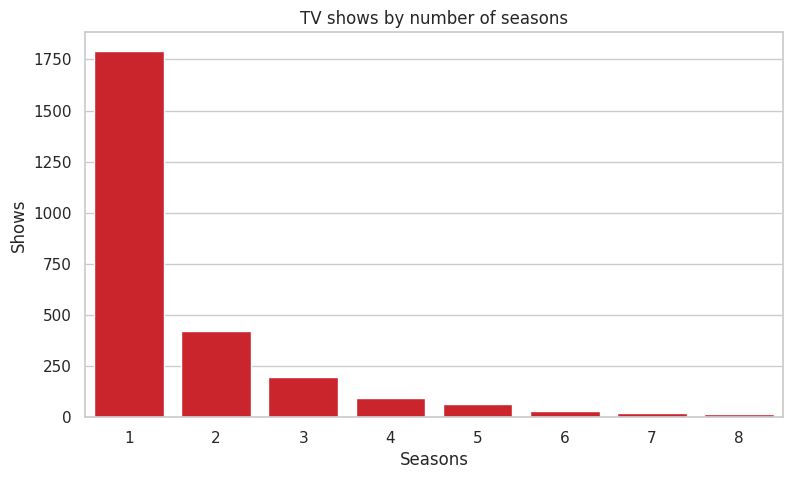

In [ ]:
s = df['seasons'].dropna().astype(int).value_counts().sort_index().head(8)
sns.barplot(x=s.index, y=s.values, color='#E50914')
plt.title('TV shows by number of seasons'); plt.xlabel('Seasons'); plt.ylabel('Shows'); plt.show()

# Viz 8, Year × Month heatmap

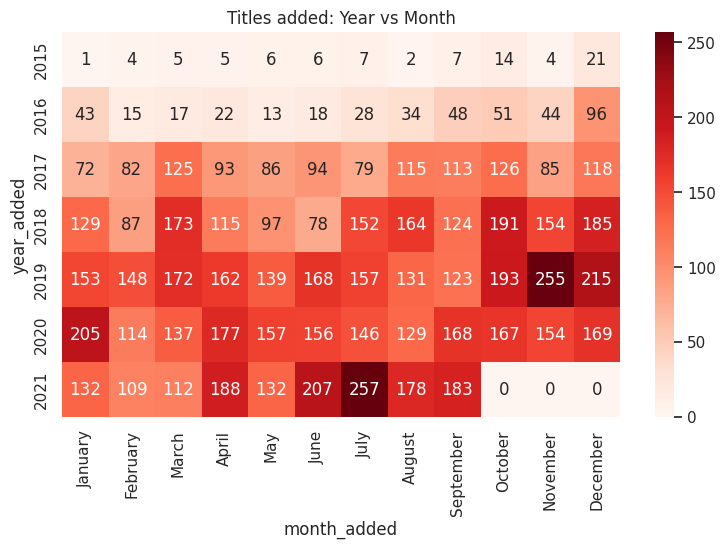

In [ ]:
months = ['January','February','March','April','May','June','July','August','September','October','November','December']
heat = df[df.year_added >= 2015].pivot_table(index='year_added', columns='month_added',
                                             values='show_id', aggfunc='count', fill_value=0)[months]
sns.heatmap(heat, cmap='Reds', annot=True, fmt='d')
plt.title('Titles added: Year vs Month'); plt.show()